In [46]:
# 01_eda.ipynb — Technical EDA (Matplotlib only)
# Author: You
# Project: Finance Customer Analytics Case Study
# Style: Plain technical (code + output)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 100)

In [18]:
df = pd.read_csv('/Users/mahithakalinathabotla/Downloads/finance-customer-analytics-case-study/data/raw/credit_card_customers.csv')
df.shape, df.head()

((1500, 16),
    customer_id  age gender           city  tenure_months  annual_income_usd  \
 0       100000   23      M   Hartford, CT             93              54209   
 1       100001   62      F     Boston, MA             80              61463   
 2       100002   55      F    Buffalo, NY            111              66816   
 3       100003   43      F   Hartford, CT            115              77096   
 4       100004   42      M  Rochester, NY             84              86617   
 
    credit_score  card_limit_usd  current_balance_usd  utilization_ratio  \
 0           676            5644              4055.16              0.718   
 1           618           13205              2447.67              0.185   
 2           628            4025              1441.39              0.358   
 3           625           12846               885.96              0.069   
 4           717            4950                 0.00              0.000   
 
    monthly_transactions  avg_transaction_value

In [20]:
# Basic info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 16 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   customer_id                1500 non-null   int64  
 1   age                        1500 non-null   int64  
 2   gender                     1500 non-null   object 
 3   city                       1500 non-null   object 
 4   tenure_months              1500 non-null   int64  
 5   annual_income_usd          1500 non-null   int64  
 6   credit_score               1500 non-null   int64  
 7   card_limit_usd             1500 non-null   int64  
 8   current_balance_usd        1500 non-null   float64
 9   utilization_ratio          1500 non-null   float64
 10  monthly_transactions       1500 non-null   int64  
 11  avg_transaction_value_usd  1500 non-null   float64
 12  late_fee_count_12m         1500 non-null   int64  
 13  complaints_12m             1500 non-null   int64

In [22]:
# Nulls and basic stats
df.isna().sum().sort_values(ascending=False).head(20)

customer_id                  0
age                          0
gender                       0
city                         0
tenure_months                0
annual_income_usd            0
credit_score                 0
card_limit_usd               0
current_balance_usd          0
utilization_ratio            0
monthly_transactions         0
avg_transaction_value_usd    0
late_fee_count_12m           0
complaints_12m               0
digital_engagement_score     0
churned                      0
dtype: int64

In [24]:
# Summary statistics (numeric)
df.describe().T

,count,mean,std,min,25%,50%,75%,max
customer_id,1500.0,100749.500000,433.157015,100000.0,100374.7500,100749.500,101124.2500,101499.00
age,1500.0,46.270667,16.473443,18.0,32.0000,46.000,61.0000,74.00
tenure_months,1500.0,59.204000,34.083674,1.0,30.0000,57.000,89.0000,119.00
annual_income_usd,1500.0,65771.387333,20032.378112,15000.0,52004.5000,65665.000,79733.0000,126770.00
credit_score,1500.0,677.223333,69.016092,460.0,630.0000,677.000,721.0000,850.00
card_limit_usd,1500.0,7962.248000,2954.754468,1000.0,5961.2500,7848.000,9947.2500,20077.00
current_balance_usd,1500.0,3657.284547,2129.417599,0.0,2122.3175,3552.735,5121.6125,10630.77
utilization_ratio,1500.0,0.540837,0.428473,0.0,0.2600,0.453,0.6875,2.00
monthly_transactions,1500.0,59.014000,34.403414,1.0,29.0000,59.000,88.2500,119.00
avg_transaction_value_usd,1500.0,44.006000,20.343103,1.0,30.0000,44.000,58.0000,114.00


In [48]:
churn_rate = df['churned'].mean()
print(f'Churn rate: {churn_rate:.2%}')

Churn rate: 3.40%


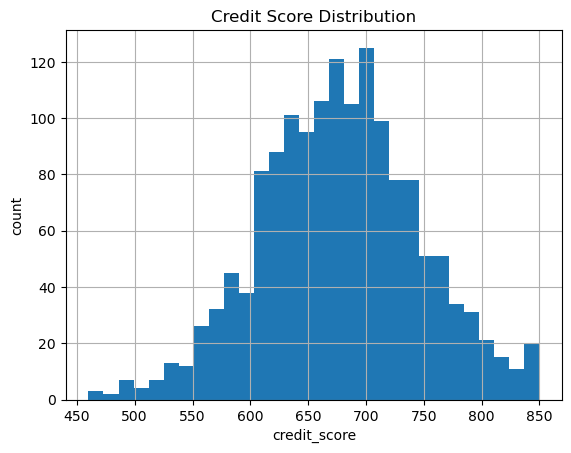

In [28]:
plt.figure()
df['credit_score'].hist(bins=30)
plt.title('Credit Score Distribution')
plt.xlabel('credit_score'); plt.ylabel('count')
plt.show()

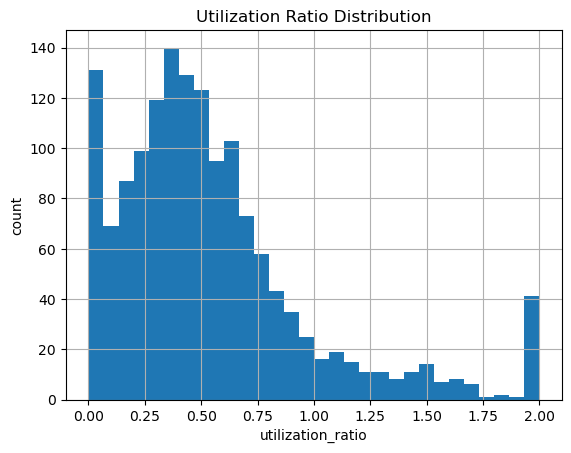

In [30]:
plt.figure()
df['utilization_ratio'].hist(bins=30)
plt.title('Utilization Ratio Distribution')
plt.xlabel('utilization_ratio'); plt.ylabel('count')
plt.show()

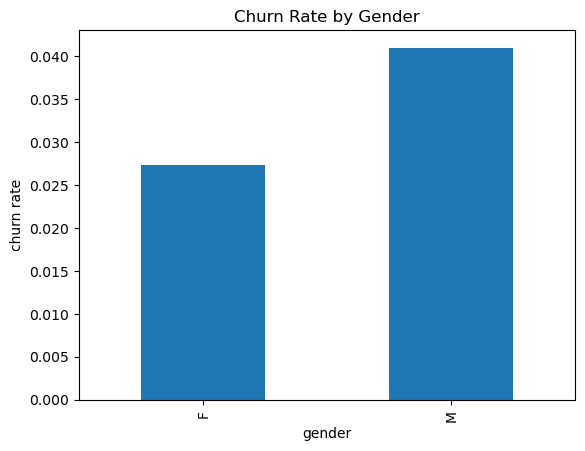

In [32]:
ax = df.groupby('gender')['churned'].mean().plot(kind='bar')
plt.title('Churn Rate by Gender')
plt.ylabel('churn rate')
plt.show()

/var/folders/qj/23sdfbzn6sz5q7s5jnxg2_940000gn/T/ipykernel_74342/50538468.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  ax = df.groupby(tenure_bins)['churned'].mean().plot(kind='bar')


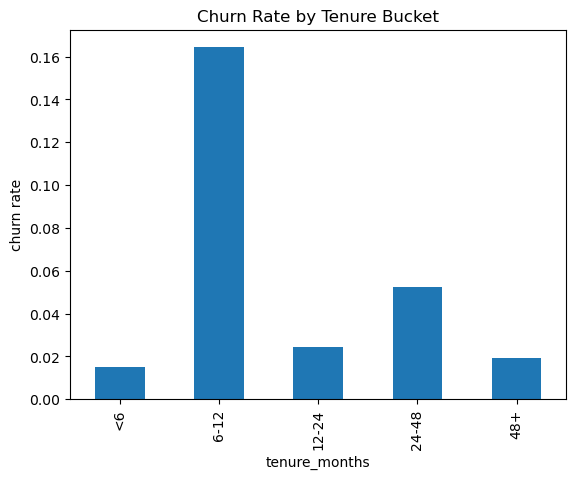

In [34]:
tenure_bins = pd.cut(df['tenure_months'], bins=[0,6,12,24,48,120], labels=['<6','6-12','12-24','24-48','48+'])
ax = df.groupby(tenure_bins)['churned'].mean().plot(kind='bar')
plt.title('Churn Rate by Tenure Bucket')
plt.ylabel('churn rate')
plt.show()

In [36]:
numeric_cols = [
    'credit_score','utilization_ratio','monthly_transactions','avg_transaction_value_usd',
    'late_fee_count_12m','complaints_12m','digital_engagement_score','tenure_months'
]
corr = df[numeric_cols + ['churned']].corr()['churned'].sort_values(ascending=False)
corr

churned                      1.000000
utilization_ratio            0.084072
avg_transaction_value_usd    0.039559
late_fee_count_12m           0.036911
complaints_12m               0.021004
credit_score                -0.020655
digital_engagement_score    -0.076340
tenure_months               -0.084364
monthly_transactions        -0.148431
Name: churned, dtype: float64

In [38]:
drivers = corr.drop('churned').abs().sort_values(ascending=False).head(5)
drivers

monthly_transactions         0.148431
tenure_months                0.084364
utilization_ratio            0.084072
digital_engagement_score     0.076340
avg_transaction_value_usd    0.039559
Name: churned, dtype: float64

In [40]:
rule = (
    (df['utilization_ratio'] > 0.9)
    | (df['late_fee_count_12m'] >= 3)
    | (df['credit_score'] < 580)
    | (df['tenure_months'] < 6)
)
screen_rate = df.loc[rule, 'churned'].mean()
coverage = rule.mean()
print(f'Heuristic segment size: {coverage:.1%} | Churn rate inside: {screen_rate:.1%}')

Heuristic segment size: 25.3% | Churn rate inside: 6.1%


In [44]:
import os
os.makedirs('../data/processed', exist_ok=True)
df.sample(200, random_state=42).to_csv(out_path, index=False)
out_path

'../data/processed/sample_customers.csv'